<a href="https://colab.research.google.com/github/yasuoThongThao7/QuanNet/blob/main/Hybrid_DehazeCNN_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pytorch-msssim
import os, time, random, zipfile, math
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pytorch_msssim import ssim as ssim_torch
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from skimage.color import rgb2lab, deltaE_ciede2000

cv2.setNumThreads(0)                      # tránh tranh CPU giữa OpenCV và DataLoader workers
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = False   # ảnh đánh giá có nhiều kích thước khác nhau, benchmark sẽ chậm
print('device:', device, '| torch', torch.__version__)

device: cpu | torch 2.11.0+cpu


## 1. Dữ liệu
Chỉ giải nén phần cần dùng (thư mục có `hazy/trans/clear` của ITS và thư mục `SOTS`) thay vì cả file zip nhiều dataset. Nếu `/content/dataset` đã có sẵn thì bỏ qua.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = '/content/drive/MyDrive/Dehaze_Project/RESIDE.zip'
DATA_DIR = '/content/dataset'
CKPT_DIR = '/content/drive/MyDrive/Dehaze_Project/Checkpoints_Dehaze_v2'
os.makedirs(CKPT_DIR, exist_ok=True)
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')

def find_its_root():
    for r, dirs, _ in os.walk(DATA_DIR):
        if {'hazy', 'trans', 'clear'} <= set(dirs):
            return r
    return None

ITS_ROOT = find_its_root() if os.path.isdir(DATA_DIR) else None
if ITS_ROOT is None:
    print('Chưa thấy ITS, đang giải nén phần cần thiết từ zip...')
    t0 = time.time()
    with zipfile.ZipFile(ZIP_PATH) as z:
        members = [m for m in z.namelist() if ('archive(1)' in m.split('/')) or ('SOTS' in m.split('/'))]
        print('số file cần giải nén:', len(members))
        z.extractall(DATA_DIR, members)
    print(f'xong sau {time.time() - t0:.0f}s')
    ITS_ROOT = find_its_root()
assert ITS_ROOT, 'Không tìm thấy thư mục chứa đủ hazy/trans/clear -> kiểm tra lại file zip'
print('ITS_ROOT =', ITS_ROOT)

# SOTS: thư mục có hazy + gt (hoặc clear), đường dẫn chứa "sots"
SOTS_DIRS = {}
for r, dirs, _ in os.walk(DATA_DIR):
    if 'sots' in r.lower() and 'hazy' in dirs and ({'gt', 'clear'} & set(dirs)):
        g = 'gt' if 'gt' in dirs else 'clear'
        name = 'indoor' if 'indoor' in r.lower() else ('outdoor' if 'outdoor' in r.lower() else os.path.basename(r))
        SOTS_DIRS[name] = (os.path.join(r, 'hazy'), os.path.join(r, g))
for k, v in SOTS_DIRS.items(): print('SOTS', k, '->', v)

Mounted at /content/drive
Chưa thấy ITS, đang giải nén phần cần thiết từ zip...
số file cần giải nén: 30922
xong sau 103s
ITS_ROOT = /content/dataset/archive(1)
SOTS indoor -> ('/content/dataset/SOTS/SOTS/indoor/hazy', '/content/dataset/SOTS/SOTS/indoor/gt')
SOTS outdoor -> ('/content/dataset/SOTS/SOTS/outdoor/hazy', '/content/dataset/SOTS/SOTS/outdoor/gt')


In [ ]:
def index_dir(d):
    return {os.path.splitext(f)[0]: os.path.join(d, f) for f in os.listdir(d) if f.lower().endswith(IMG_EXT)}

def load_rgb(p, hw=None):
    img = cv2.imread(p, cv2.IMREAD_COLOR)
    assert img is not None, f'không đọc được ảnh: {p}'
    img = np.ascontiguousarray(img[..., ::-1])                     # BGR -> RGB, uint8
    if hw is not None and img.shape[:2] != tuple(hw):
        img = cv2.resize(img, (hw[1], hw[0]), interpolation=cv2.INTER_AREA)
    return img

def load_trans(p, hw=None):
    raw = cv2.imread(p, cv2.IMREAD_UNCHANGED)
    assert raw is not None, f'không đọc được trans: {p}'
    if raw.ndim == 3: raw = raw[..., 0]
    scale = 65535. if raw.dtype == np.uint16 else 255.
    t = raw.astype(np.float32) / scale
    if hw is not None and t.shape != tuple(hw):
        t = cv2.resize(t, (hw[1], hw[0]), interpolation=cv2.INTER_LINEAR)
    return t

# Quy ước RESIDE-ITS:  hazy {id}_{k}_{A}.png | trans {id}_{k}.png | clear {id}.png
def build_its(root):
    hz = index_dir(os.path.join(root, 'hazy'))
    tr = index_dir(os.path.join(root, 'trans'))
    cl = index_dir(os.path.join(root, 'clear'))
    print('số file  hazy/trans/clear:', len(hz), len(tr), len(cl))
    print('mẫu hazy :', sorted(hz)[:3]); print('mẫu trans:', sorted(tr)[:3]); print('mẫu clear:', sorted(cl)[:3])
    items, rule_count, missing = [], {}, 0
    for stem, p in sorted(hz.items()):
        parts = stem.split('_')
        sid = parts[0]
        tkey = '_'.join(parts[:2])
        try: A = float(parts[2]) if len(parts) >= 3 else None
        except ValueError: A = None
        cands = [tkey, stem, tkey + '_trans', sid + '_trans', sid]          # thứ tự ưu tiên
        rule = next((i for i, c in enumerate(cands) if c in tr), None)
        cp = cl.get(sid) or cl.get(stem)
        if rule is None or cp is None:
            missing += 1; continue
        key = ['id_k', 'ten_day_du', 'id_k_trans', 'id_trans', 'id'][rule]
        rule_count[key] = rule_count.get(key, 0) + 1
        items.append(dict(hazy=p, trans=tr[cands[rule]], clear=cp, id=sid, A=A))
    print('ghép được:', len(items), '| thiếu:', missing, '| quy tắc ghép trans:', rule_count)
    if len(items) < 0.99 * len(hz):
        raise RuntimeError('Ghép cặp thất bại (>1% thiếu). Hãy gửi cho mình các tên file mẫu ở trên để chỉnh quy tắc tên.')
    return items

its_items = build_its(ITS_ROOT)

# Tách train/val theo ID cảnh (cùng cách tách với notebook DehazeNet trước, để so sánh công bằng)
ids = sorted({it['id'] for it in its_items})
random.Random(SEED).shuffle(ids)
n_val = max(20, int(0.05 * len(ids)))
val_ids = set(ids[:n_val])
train_items = [it for it in its_items if it['id'] not in val_ids]
val_items = [it for it in its_items if it['id'] in val_ids]
print(f'train: {len(train_items)} | val: {len(val_items)} ({n_val} cảnh)')

số file  hazy/trans/clear: 13990 13990 1399
mẫu hazy : ['1000_10_0.74905', '1000_1_0.99837', '1000_2_0.96419']
mẫu trans: ['1000_1', '1000_10', '1000_2']
mẫu clear: ['1', '10', '100']
ghép được: 13990 | thiếu: 0 | quy tắc ghép trans: {'id_k': 13990}
train: 13300 | val: 690 (69 cảnh)


trans GT: mean 0.527 | std trung bình 0.105 | min 0.169 | max 0.937
sai số tái tạo I = J*t + A*(1-t): trung bình 0.000002 (nhỏ, cỡ <1e-3, là ghép đúng)


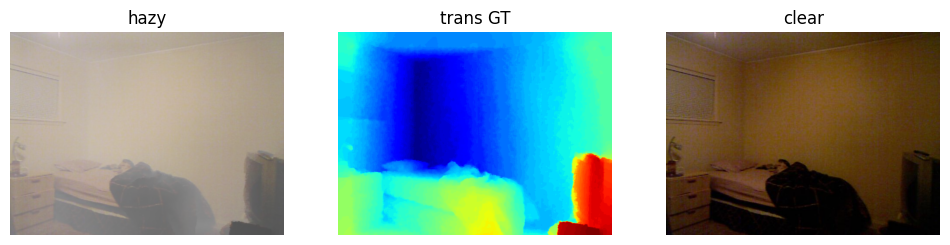

In [ ]:
# ---------- KIỂM TRA NHÃN (đây là thứ bản cũ thiếu) ----------
# 1) Nhãn trans phải có biến thiên thật (không phải ảnh trắng)
st = []
for it in random.Random(0).sample(its_items, 30):
    t = load_trans(it['trans']); st.append((t.mean(), t.std(), t.min(), t.max()))
st = np.array(st)
print('trans GT: mean %.3f | std trung bình %.3f | min %.3f | max %.3f' % (st[:, 0].mean(), st[:, 1].mean(), st[:, 2].min(), st[:, 3].max()))
assert st[:, 1].mean() > 0.02, 'Nhãn trans gần như phẳng (std~0) -> ghép sai file hoặc nhãn là ảnh trắng!'

# 2) Kiểm tra chéo vật lý: I = J*t + A*(1-t) với A lấy từ tên file hazy
errs = []
for it in random.Random(1).sample(its_items, 20):
    if it['A'] is None: continue
    I = load_rgb(it['hazy']).astype(np.float32) / 255.
    J = load_rgb(it['clear'], I.shape[:2]).astype(np.float32) / 255.
    t = load_trans(it['trans'], I.shape[:2])[..., None]
    errs.append(float(np.mean((I - (J * t + it['A'] * (1 - t))) ** 2)))
if errs:
    print('sai số tái tạo I = J*t + A*(1-t): trung bình %.6f' % np.mean(errs), '(nhỏ, cỡ <1e-3, là ghép đúng)')
    if np.mean(errs) > 5e-3:
        print('CẢNH BÁO: sai số lớn -> có thể ghép nhầm trans/clear hoặc A trong tên file không phải ánh sáng khí quyển.')

s = random.Random(2).choice(its_items)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, x, n in zip(ax, (load_rgb(s['hazy']), load_trans(s['trans']), load_rgb(s['clear'])), ('hazy', 'trans GT', 'clear')):
    a.imshow(x, cmap='jet' if x.ndim == 2 else None); a.set_title(n); a.axis('off')
plt.show()

## 2. DCP trên GPU + Dataset nhanh
- `A` (ánh sáng khí quyển) ước lượng **một lần cho cả ảnh** trên bản thu nhỏ 1/4 (rất rẻ), cùng hàm dùng cho cả train và test.
- Dark channel / transmission thô tính **trên GPU** bằng min-pooling (`-maxpool(-x)`), sau khi cắt crop.
- Mỗi ảnh cho nhiều crop 256×256 (giải mã ảnh 1 lần, dùng nhiều lần). Không đọc ảnh `clear` khi train.

In [ ]:
PATCH = 256
CROPS = 4          # số crop / ảnh
BATCH_IMGS = 8     # 8 ảnh x 4 crop = 32 patch / batch
M = 8              # viền bỏ qua trong loss (cửa sổ DCP 15x15 bị cắt ở mép crop)

def estimate_A_np(img_u8, scale=0.25, k=5, percent=0.1):
    # Ánh sáng khí quyển: trung bình màu của 0.1% pixel có dark channel lớn nhất (tính trên ảnh thu nhỏ)
    small = cv2.resize(img_u8, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA).astype(np.float32) / 255.
    dark = cv2.erode(small.min(2), np.ones((k, k), np.uint8))
    n = max(int(dark.size * percent / 100), 1)
    idx = np.argpartition(dark.ravel(), -n)[-n:]
    return small.reshape(-1, 3)[idx].mean(0).astype(np.float32)

def min_filter(x, k=15):
    return -F.max_pool2d(-x, k, stride=1, padding=k // 2)       # erode trên GPU

def dcp_inputs(x, A, omega=0.95, k=15):
    # x: (B,3,H,W) trong [0,1]; A: (B,3,1,1)
    dark = min_filter(x.min(1, keepdim=True)[0], k)
    dark_n = min_filter((x / A.clamp_min(1e-3)).min(1, keepdim=True)[0], k)
    return dark, (1 - omega * dark_n).clamp(0, 1)

def make_input(hz_u8, A):
    # hz_u8: (N,3,H,W) uint8 trên GPU; A: (N,3)
    x = hz_u8.float() / 255.
    dark, tr = dcp_inputs(x, A.view(-1, 3, 1, 1))
    return torch.cat([x, dark, tr], 1)

class ITSHybrid(Dataset):
    def __init__(self, items, patch=PATCH, crops=CROPS):
        self.items, self.patch, self.crops = items, patch, crops
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        it = self.items[i]
        img = load_rgb(it['hazy'])
        t = load_trans(it['trans'], img.shape[:2])
        H, W = t.shape
        if min(H, W) < self.patch:                                   # ảnh nhỏ hơn crop -> phóng to
            s = self.patch / min(H, W) + 1e-3
            img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
            t = cv2.resize(t, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_LINEAR)
            H, W = t.shape
        A = estimate_A_np(img)
        xs, ts = [], []
        for _ in range(self.crops):
            y, x = random.randint(0, H - self.patch), random.randint(0, W - self.patch)
            ci, ct = img[y:y + self.patch, x:x + self.patch], t[y:y + self.patch, x:x + self.patch]
            if random.random() < 0.5:                                # chỉ lật ngang (lật dọc làm sai quy luật trời/đất)
                ci, ct = ci[:, ::-1], ct[:, ::-1]
            xs.append(np.ascontiguousarray(ci)); ts.append(np.ascontiguousarray(ct))
        hz = torch.from_numpy(np.stack(xs)).permute(0, 3, 1, 2).contiguous()      # uint8 (K,3,H,W)
        tt = torch.from_numpy(np.stack(ts))[:, None].contiguous()                  # float32 (K,1,H,W)
        return hz, tt, torch.from_numpy(A)

## 3. Mô hình: Hybrid CNN dạng *residual* trên `trans_raw`
`t = clamp(trans_raw_DCP + CNN(RGB, dark, trans_raw), 0, 1)`. Lớp cuối khởi tạo bằng 0 nên mô hình **bắt đầu đúng bằng DCP**. Dùng dilation (1,2,4) để thấy ngữ cảnh rộng hơn (~17 px) mà vẫn nhẹ (~20k tham số). Clamp kiểu straight-through: giá trị đầu ra vẫn thuộc [0,1] nhưng gradient không bao giờ bằng 0.

In [ ]:
class HybridTransmissionCNN(nn.Module):
    def __init__(self, ch=32):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(5, ch, 3, padding=1), nn.PReLU(ch),
            nn.Conv2d(ch, ch, 3, padding=2, dilation=2), nn.PReLU(ch),
            nn.Conv2d(ch, ch, 3, padding=4, dilation=4), nn.PReLU(ch),
            nn.Conv2d(ch, 1, 3, padding=1))
        nn.init.zeros_(self.body[-1].weight); nn.init.zeros_(self.body[-1].bias)   # bắt đầu = DCP
    def forward(self, x):
        t = x[:, 4:5] + self.body(x)               # x[:,4] là trans_raw của DCP
        t_hard = t.clamp(0., 1.)
        if not self.training:
            return t_hard
        return t + (t_hard - t).detach()           # straight-through: giá trị = t_hard, gradient luôn thông

def loss_fn(pred, gt):
    mse = F.mse_loss(pred, gt)
    ssim_v = ssim_torch(pred, gt, data_range=1.0, size_average=True)
    return mse + 0.1 * (1.0 - ssim_v), mse

model = HybridTransmissionCNN().to(device)
print('số tham số:', sum(p.numel() for p in model.parameters()))

số tham số: 20353


In [ ]:
# ---------- Suy luận ảnh đầy đủ + khôi phục ----------
def sync():
    if device.type == 'cuda': torch.cuda.synchronize()

@torch.no_grad()
def predict_t(model, img_u8, A):
    # trả về (t của CNN, t thô của DCP), cả hai HxW float32
    x = torch.from_numpy(np.ascontiguousarray(img_u8)).permute(2, 0, 1)[None].to(device).float() / 255.
    At = torch.from_numpy(A).to(device).view(1, 3, 1, 1)
    dark, tr = dcp_inputs(x, At)
    t_net = model(torch.cat([x, dark, tr], 1))
    return t_net[0, 0].float().cpu().numpy(), tr[0, 0].float().cpu().numpy()

def box(x, r):
    return cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1), borderType=cv2.BORDER_REFLECT)

def guided_filter(I, p, r, eps):
    mI, mp = box(I, r), box(p, r)
    cov, var = box(I * p, r) - mI * mp, box(I * I, r) - mI * mI
    a = cov / (var + eps); b = mp - a * mI
    return box(a, r) * I + box(b, r)

def recover(img, t, A, t_min=0.1):                     # J = (I - A)/t + A
    t = np.clip(t, t_min, 1.0)[..., None]
    return np.clip((img - A) / t + A, 0, 1)

def img_metrics(pred, gt):
    return dict(PSNR=psnr_fn(gt, pred, data_range=1.0),
                SSIM=ssim_fn(gt, pred, channel_axis=2, data_range=1.0),
                CIEDE2000=float(deltaE_ciede2000(rgb2lab(gt), rgb2lab(pred)).mean()))

GF_R, GF_EPS = 20, 1e-3        # guided filter (bán kính 20 ≈ cửa sổ 40 ở bản cũ)

## 4. Kiểm tra trước khi train
Ba điều phải đúng: (1) nhãn có biến thiên, (2) loss ban đầu **thấp** (≈ chất lượng DCP) chứ không phải ~0.99, (3) gradient khác 0 và mô hình khởi tạo cho kết quả **trùng DCP** trên tập validation.

In [ ]:
# Cache validation (100 ảnh full-size) trong RAM
val_sub = random.Random(0).sample(val_items, min(100, len(val_items)))
val_cache = []
for it in tqdm(val_sub, desc='cache val'):
    img = load_rgb(it['hazy'])
    val_cache.append((img, estimate_A_np(img), load_trans(it['trans'], img.shape[:2])))

@torch.no_grad()
def validate(model):
    was_training = model.training; model.eval()
    m_net, m_dcp = [], []
    for img, A, tg in val_cache:
        t_net, t_dcp = predict_t(model, img, A)
        m_net.append(((t_net - tg) ** 2).mean()); m_dcp.append(((t_dcp - tg) ** 2).mean())
    if was_training: model.train()
    return float(np.mean(m_net)), float(np.mean(m_dcp))

v0, dcp_base = validate(model)
print(f'val t-MSE  | mô hình khởi tạo: {v0:.5f} | DCP thuần (baseline cần vượt): {dcp_base:.5f}')
assert abs(v0 - dcp_base) < 1e-4, 'Mô hình khởi tạo phải trùng DCP - kiểm tra lại pipeline!'

# 1 batch thử: loss ban đầu + gradient
dbg = DataLoader(ITSHybrid(train_items[:BATCH_IMGS]), batch_size=BATCH_IMGS, num_workers=0)
hz, tg, A = next(iter(dbg))
B, K = hz.shape[:2]
hz, tg = hz.flatten(0, 1).to(device), tg.flatten(0, 1).to(device)
A = A.to(device).unsqueeze(1).expand(B, K, 3).reshape(B * K, 3)
print('nhãn trong batch: mean %.3f | std %.3f | min %.3f | max %.3f' % (tg.mean(), tg.std(), tg.min(), tg.max()))
model.train()
with torch.no_grad(): inp = make_input(hz, A)
pred = model(inp)
loss, mse = loss_fn(pred[..., M:-M, M:-M], tg[..., M:-M, M:-M])
loss.backward()
gn = model.body[-1].weight.grad.norm().item()
print(f'loss ban đầu = {loss.item():.4f} (MSE {mse.item():.4f}) | grad lớp cuối = {gn:.4e}')
assert loss.item() < 0.5, 'Loss ban đầu quá cao: nhãn/đầu vào đang sai (xem lại cell kiểm tra nhãn)'
assert gn > 0, 'Gradient bằng 0!'
model.zero_grad(set_to_none=True)
del dbg

cache val:   0%|          | 0/100 [00:00<?, ?it/s]

val t-MSE  | mô hình khởi tạo: 0.02778 | DCP thuần (baseline cần vượt): 0.02778
nhãn trong batch: mean 0.484 | std 0.140 | min 0.180 | max 0.733
loss ban đầu = 0.0287 (MSE 0.0149) | grad lớp cuối = 1.0670e-01


## 5. Huấn luyện
Mỗi "epoch" lấy ngẫu nhiên `IMGS_PER_EPOCH` ảnh (không cần quét hết 13k ảnh mỗi lượt). Cuối mỗi epoch in **val t-MSE của mô hình so với DCP**: mô hình đúng thì con số này phải **giảm xuống dưới baseline DCP** sau vài epoch.

resume từ epoch 30
500 iter/epoch | baseline DCP val t-MSE = 0.02778


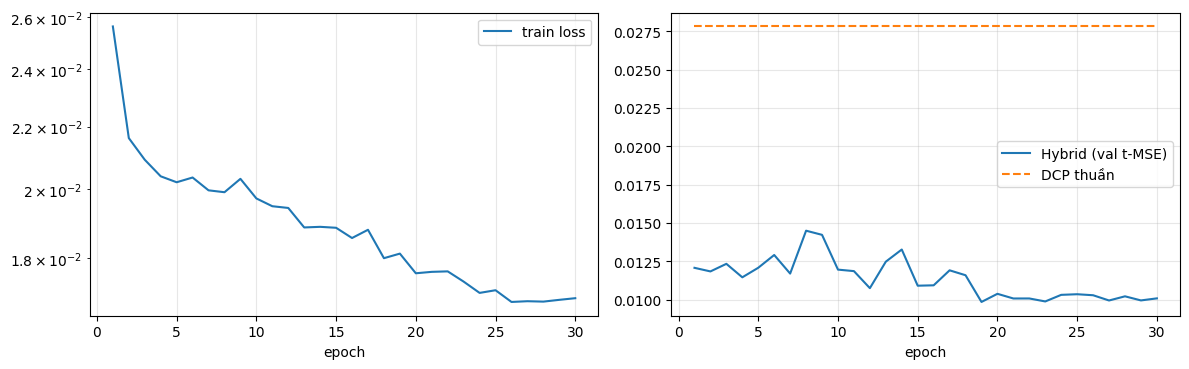

đã nạp best: val t-MSE = 0.00986 so với DCP 0.02778


In [ ]:
EPOCHS = 30
IMGS_PER_EPOCH = 4000
LR = 1e-3
NUM_WORKERS = 2
#RESUME = False
RESUME = True   # true
ds = ITSHybrid(train_items)
loader = DataLoader(ds, batch_size=BATCH_IMGS,
                    sampler=RandomSampler(ds, replacement=False, num_samples=min(IMGS_PER_EPOCH, len(ds))),
                    num_workers=NUM_WORKERS, drop_last=True, pin_memory=(device.type == 'cuda'),
                    persistent_workers=NUM_WORKERS > 0, prefetch_factor=4 if NUM_WORKERS > 0 else None)

model = HybridTransmissionCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(loader), eta_min=1e-5)

best_path = os.path.join(CKPT_DIR, 'hybrid_best.pth')
last_path = os.path.join(CKPT_DIR, 'hybrid_last.pth')
history, best, start_epoch = [], 1e9, 0
if RESUME and os.path.exists(last_path):
    ck = torch.load(last_path, map_location=device, weights_only=False)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
    history, best, start_epoch = ck['history'], ck['best'], ck['epoch'] + 1
    print('resume từ epoch', start_epoch)

print(f'{len(loader)} iter/epoch | baseline DCP val t-MSE = {dcp_base:.5f}')
for ep in range(start_epoch, EPOCHS):
    model.train(); t0 = time.time(); run = run_mse = 0.; n = 0
    for hz, tg, A in tqdm(loader, desc=f'epoch {ep + 1}/{EPOCHS}', leave=False):
        B, K = hz.shape[:2]
        hz = hz.flatten(0, 1).to(device, non_blocking=True)
        tg = tg.flatten(0, 1).to(device, non_blocking=True)
        A = A.to(device, non_blocking=True).unsqueeze(1).expand(B, K, 3).reshape(B * K, 3)
        with torch.no_grad():
            inp = make_input(hz, A)
        pred = model(inp)
        loss, mse = loss_fn(pred[..., M:-M, M:-M], tg[..., M:-M, M:-M])
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        run += loss.item(); run_mse += mse.item(); n += 1
    v_net, v_dcp = validate(model)
    history.append(dict(epoch=ep + 1, train_loss=run / n, train_mse=run_mse / n, val_t_mse=v_net, val_t_mse_dcp=v_dcp, sec=time.time() - t0))
    flag = ''
    if v_net < best:
        best = v_net; torch.save(model.state_dict(), best_path); flag = '  <- best'
    print(f'epoch {ep + 1:2d}: loss {run / n:.5f} | train MSE {run_mse / n:.5f} | val t-MSE {v_net:.5f} (DCP {v_dcp:.5f}) | {time.time() - t0:.0f}s{flag}')
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    history=history, best=best, epoch=ep), last_path)

hist = pd.DataFrame(history); hist.to_csv(os.path.join(CKPT_DIR, 'train_history.csv'), index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(hist.epoch, hist.train_loss, label='train loss'); ax[0].set_yscale('log'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist.epoch, hist.val_t_mse, label='Hybrid (val t-MSE)'); ax[1].plot(hist.epoch, hist.val_t_mse_dcp, '--', label='DCP thuần')
ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()

model.load_state_dict(torch.load(best_path, map_location=device)); model.eval()
print('đã nạp best: val t-MSE = %.5f so với DCP %.5f' % (best, dcp_base))

## 6. Đánh giá và so sánh
Các phương pháp trên cùng một ảnh: **Hazy**, **DCP cổ điển (+GF)**, **Hybrid CNN (thô)**, **Hybrid CNN + GF (đầy đủ)**, và **Oracle** (t thật + A thật, chỉ cho ITS-val, để chẩn đoán).
Tiêu chí: t-MSE/MAE (mức bản đồ truyền qua), PSNR, SSIM, CIEDE2000 (mức ảnh khôi phục), thời gian xử lý và số tham số.

In [ ]:
def build_sots(hd, gd):
    hz, gt = index_dir(hd), index_dir(gd)
    return [dict(hazy=p, clear=gt[s.split('_')[0]], trans=None, A=None, id=s)
            for s, p in sorted(hz.items()) if s.split('_')[0] in gt]

def evaluate(items, model, n=None, oracle=False, desc='eval'):
    model.eval(); rows = []
    sub = items if n is None else random.Random(1).sample(items, min(n, len(items)))
    for it in tqdm(sub, desc=desc):
        img_u8 = load_rgb(it['hazy']); img = img_u8.astype(np.float32) / 255.
        gt = load_rgb(it['clear'], img.shape[:2]).astype(np.float32) / 255.
        A = estimate_A_np(img_u8)
        sync(); t0 = time.time()
        t_net, t_dcp = predict_t(model, img_u8, A)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        t_net_gf = np.clip(guided_filter(gray, t_net, GF_R, GF_EPS), 0, 1)
        J = recover(img, t_net_gf, A)
        sync(); dt = time.time() - t0
        t_dcp_gf = np.clip(guided_filter(gray, t_dcp, GF_R, GF_EPS), 0, 1)

        tg = load_trans(it['trans'], img.shape[:2]) if it.get('trans') else None
        def tm(t): return dict(T_MSE=float(((t - tg) ** 2).mean()), T_MAE=float(np.abs(t - tg).mean())) if tg is not None else {}
        base = dict(id=it['id'], file=os.path.basename(it['hazy']))
        rows.append({**base, 'method': '1. Hazy (không khử)', **img_metrics(img, gt)})
        rows.append({**base, 'method': '2. DCP cổ điển (+GF)', **img_metrics(recover(img, t_dcp_gf, A), gt), **tm(t_dcp_gf)})
        rows.append({**base, 'method': '3. Hybrid CNN (thô)', **img_metrics(recover(img, t_net, A), gt), **tm(t_net)})
        rows.append({**base, 'method': '4. Hybrid CNN + GF (đầy đủ)', **img_metrics(J, gt), **tm(t_net_gf), 'time_s': dt})
        if oracle and tg is not None:
            Ao = np.array([it['A']] * 3, np.float32) if it.get('A') else estimate_A_np(img_u8)
            rows.append({**base, 'method': '5. Oracle (t GT + A GT)', **img_metrics(recover(img, tg, Ao), gt)})
    return pd.DataFrame(rows)

def summarize(df):
    cols = [c for c in ['PSNR', 'SSIM', 'CIEDE2000', 'T_MSE', 'T_MAE', 'time_s'] if c in df]
    return df.groupby('method')[cols].mean().round(4)

all_results = {}
all_results['ITS-val'] = evaluate(val_items, model, n=300, oracle=True, desc='ITS-val')     # n=None để chạy toàn bộ tập val
print('=== ITS validation ==='); display(summarize(all_results['ITS-val']))

ITS-val:   0%|          | 0/300 [00:00<?, ?it/s]

=== ITS validation ===


,PSNR,SSIM,CIEDE2000,T_MSE,T_MAE,time_s
method,,,,,,
1. Hazy (không khử),12.8710,0.6900,19.5242,NaN,NaN,NaN
2. DCP cổ điển (+GF),16.7880,0.8065,11.6887,0.0273,0.1180,NaN
3. Hybrid CNN (thô),19.1019,0.8168,9.3496,0.0120,0.0822,NaN
4. Hybrid CNN + GF (đầy đủ),19.3849,0.8344,9.2309,0.0112,0.0802,0.9796
5. Oracle (t GT + A GT),51.7343,0.9952,0.4905,NaN,NaN,NaN


In [ ]:
sots_cache = {}
for name, (hd, gd) in SOTS_DIRS.items():
    items = build_sots(hd, gd)
    print(f'SOTS {name}: {len(items)} cặp')
    if not items: continue
    all_results['SOTS-' + name] = evaluate(items, model, desc='SOTS ' + name); sots_cache[name] = items
    print(f'=== SOTS {name} ==='); display(summarize(all_results['SOTS-' + name]))

final = pd.concat([summarize(d).assign(dataset=k).reset_index() for k, d in all_results.items()])
final = final[['dataset', 'method'] + [c for c in final.columns if c not in ('dataset', 'method')]]
final.to_csv(os.path.join(CKPT_DIR, 'final_results.csv'), index=False)
for k, d in all_results.items(): d.to_csv(os.path.join(CKPT_DIR, f'per_image_{k}.csv'), index=False)
print('Số tham số Hybrid CNN:', sum(p.numel() for p in model.parameters()))
display(final)

SOTS indoor: 500 cặp


SOTS indoor:   0%|          | 0/500 [00:00<?, ?it/s]

=== SOTS indoor ===


,PSNR,SSIM,CIEDE2000,time_s
method,,,,
1. Hazy (không khử),11.9748,0.6934,20.3176,NaN
2. DCP cổ điển (+GF),19.4067,0.8609,7.5680,NaN
3. Hybrid CNN (thô),21.4983,0.8606,6.0745,NaN
4. Hybrid CNN + GF (đầy đủ),21.9199,0.8782,5.9469,0.9691


SOTS outdoor: 500 cặp


SOTS outdoor:   0%|          | 0/500 [00:00<?, ?it/s]

=== SOTS outdoor ===


,PSNR,SSIM,CIEDE2000,time_s
method,,,,
1. Hazy (không khử),15.9194,0.8139,12.9834,NaN
2. DCP cổ điển (+GF),16.8549,0.8552,10.6561,NaN
3. Hybrid CNN (thô),19.7052,0.8311,8.1742,NaN
4. Hybrid CNN + GF (đầy đủ),20.1514,0.8476,8.0211,0.7391


Số tham số Hybrid CNN: 20353


,dataset,method,PSNR,SSIM,CIEDE2000,T_MSE,T_MAE,time_s
0,ITS-val,1. Hazy (không khử),12.8710,0.6900,19.5242,NaN,NaN,NaN
1,ITS-val,2. DCP cổ điển (+GF),16.7880,0.8065,11.6887,0.0273,0.1180,NaN
2,ITS-val,3. Hybrid CNN (thô),19.1019,0.8168,9.3496,0.0120,0.0822,NaN
3,ITS-val,4. Hybrid CNN + GF (đầy đủ),19.3849,0.8344,9.2309,0.0112,0.0802,0.9796
4,ITS-val,5. Oracle (t GT + A GT),51.7343,0.9952,0.4905,NaN,NaN,NaN
0,SOTS-indoor,1. Hazy (không khử),11.9748,0.6934,20.3176,NaN,NaN,NaN
1,SOTS-indoor,2. DCP cổ điển (+GF),19.4067,0.8609,7.5680,NaN,NaN,NaN
2,SOTS-indoor,3. Hybrid CNN (thô),21.4983,0.8606,6.0745,NaN,NaN,NaN
3,SOTS-indoor,4. Hybrid CNN + GF (đầy đủ),21.9199,0.8782,5.9469,NaN,NaN,0.9691
0,SOTS-outdoor,1. Hazy (không khử),15.9194,0.8139,12.9834,NaN,NaN,NaN


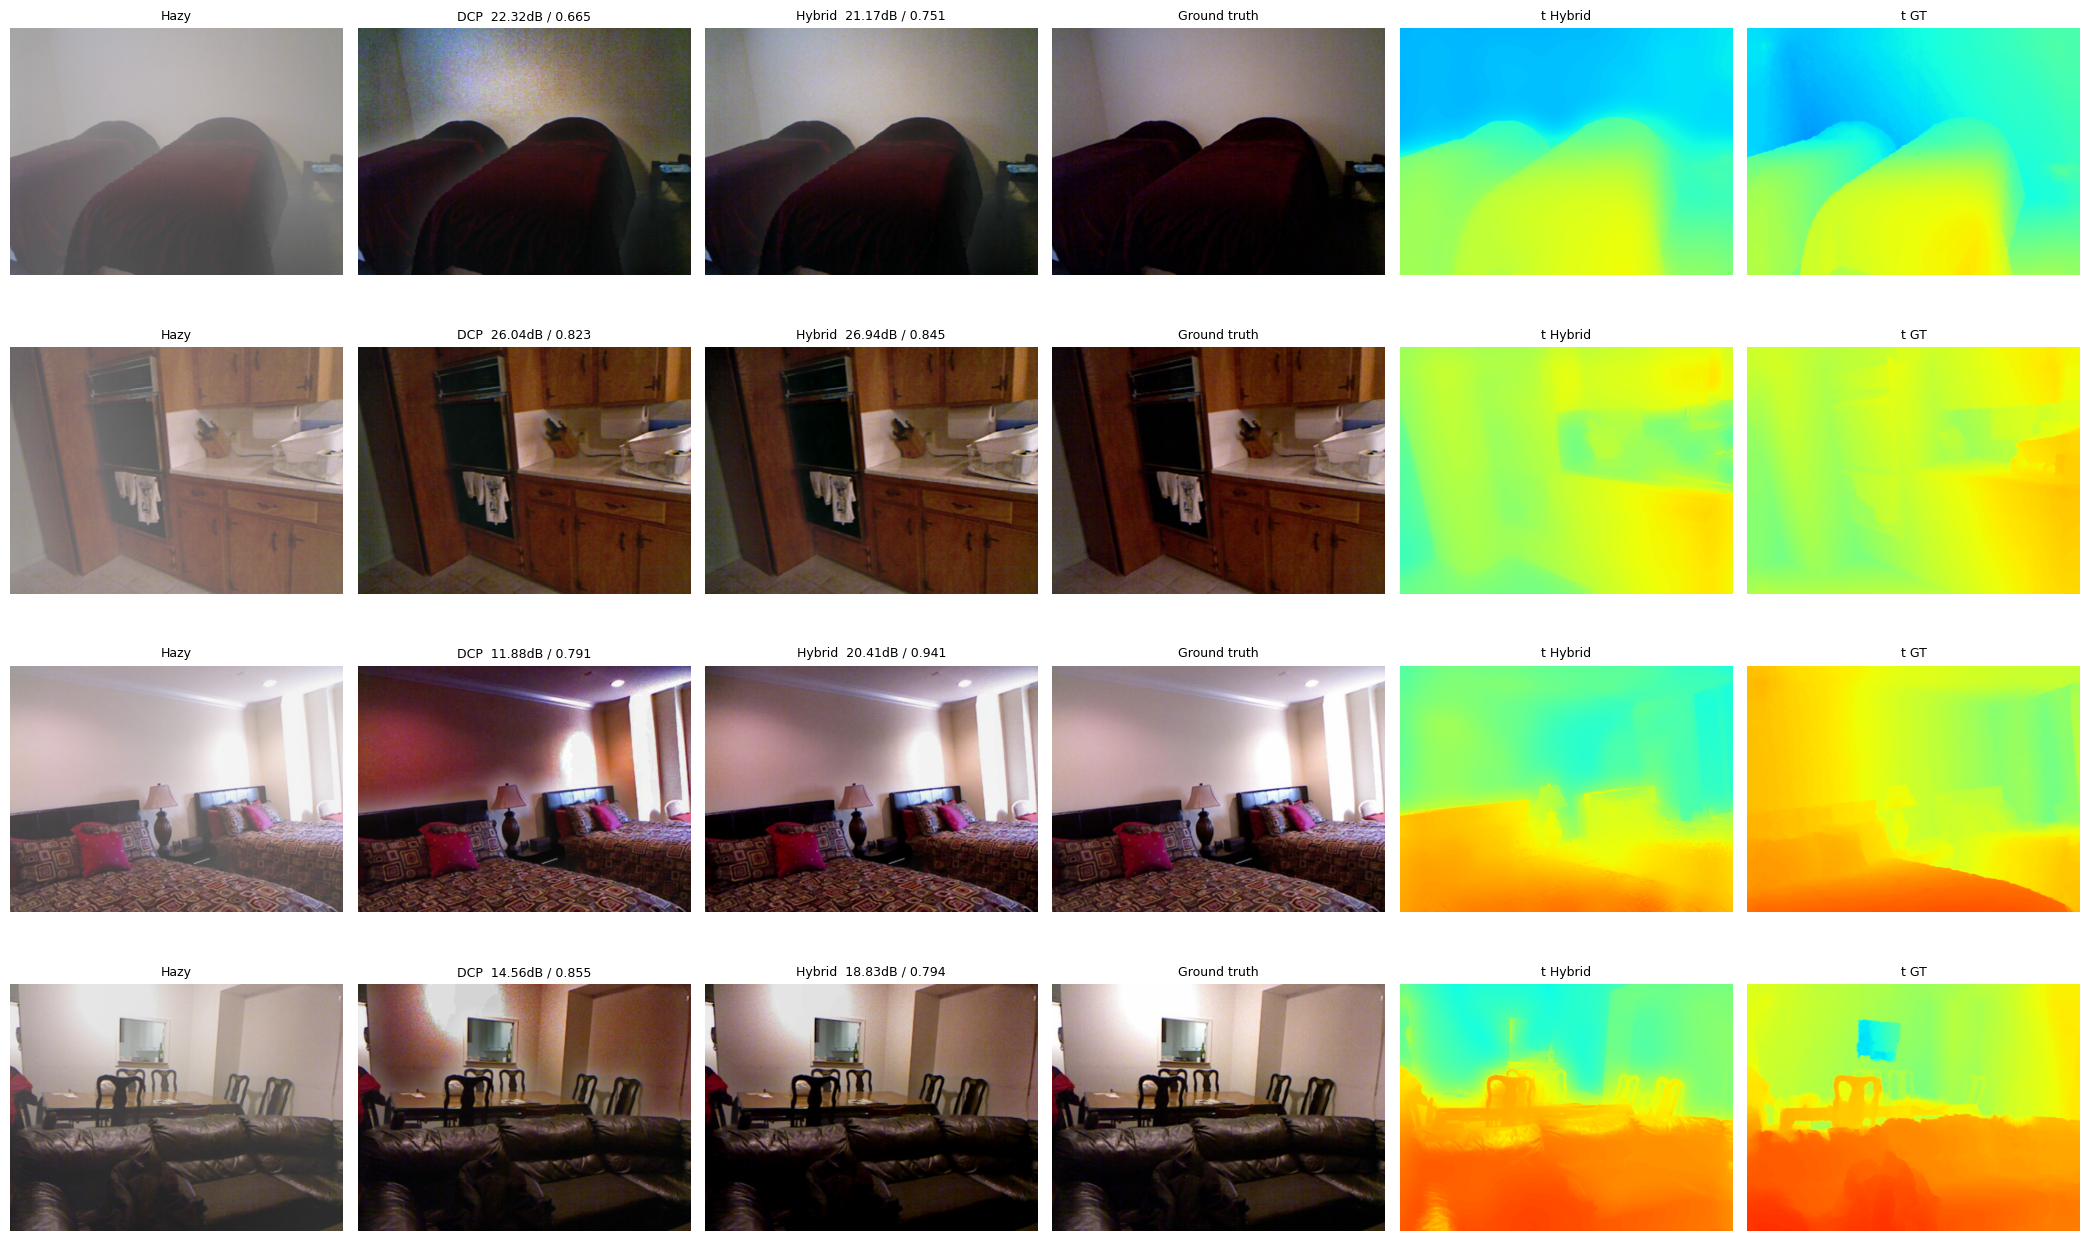

SOTS indoor


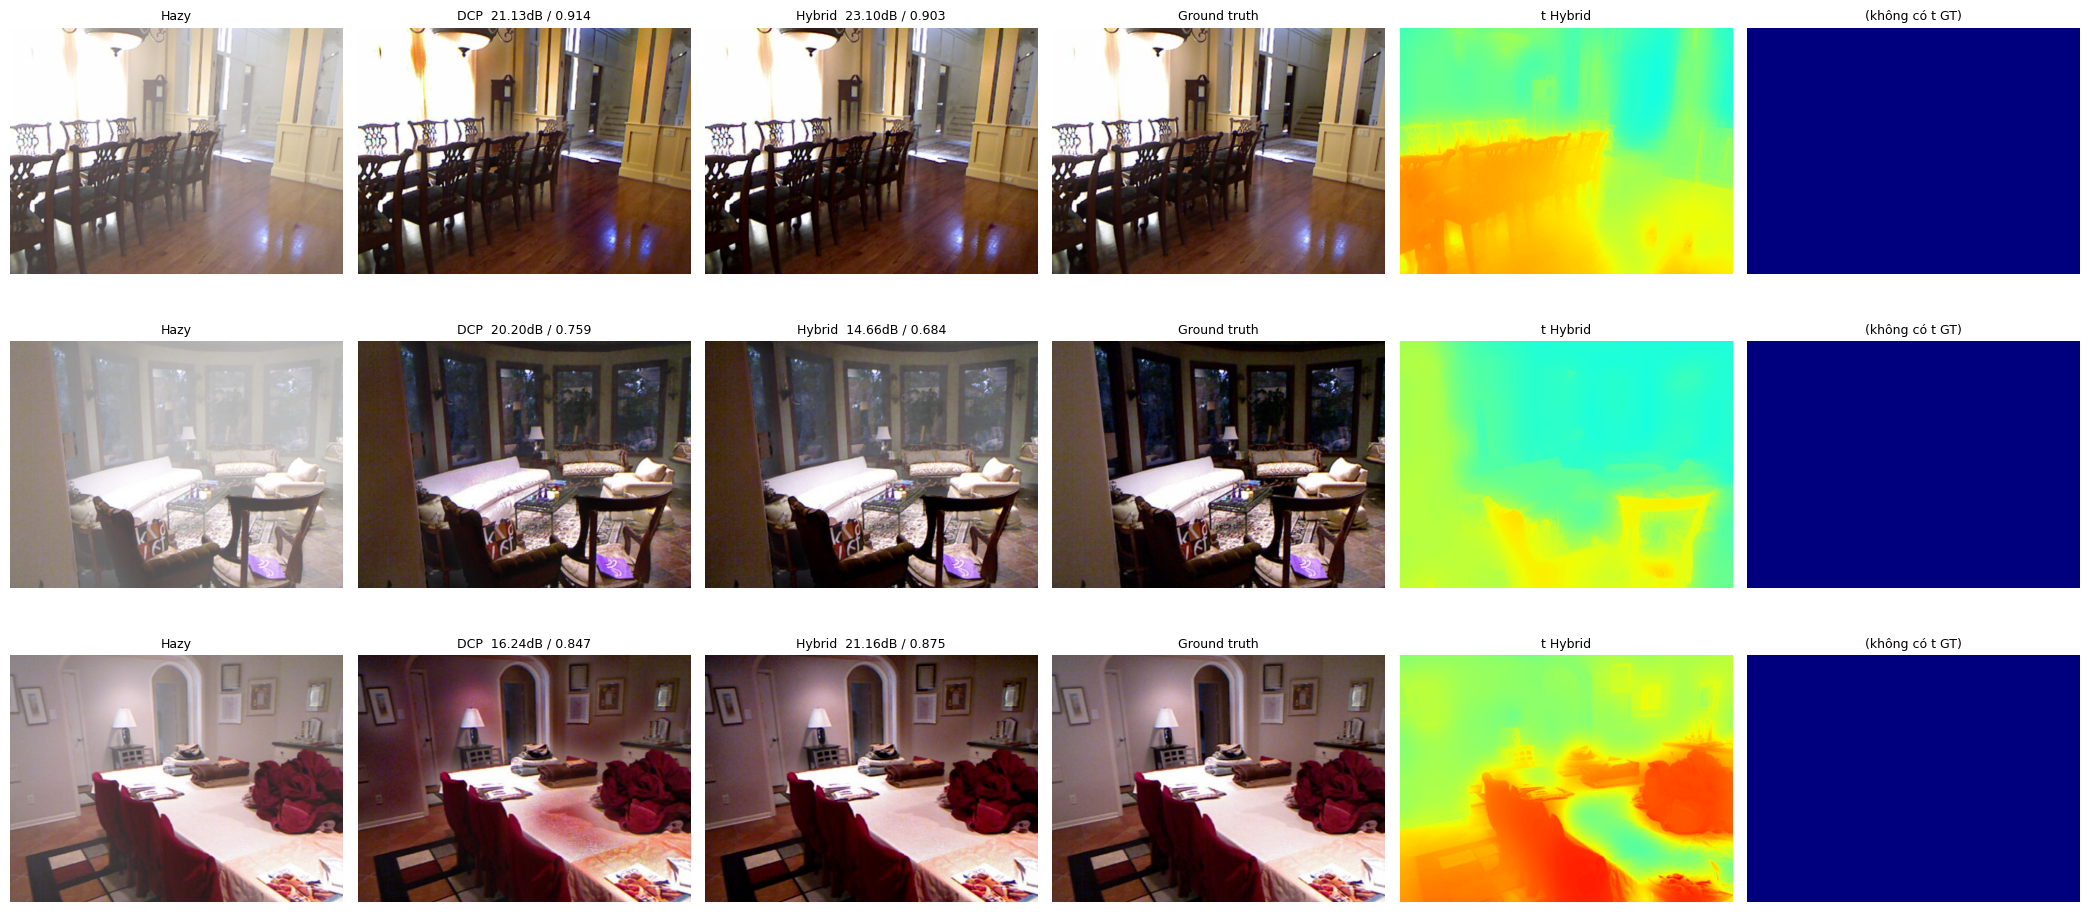

SOTS outdoor


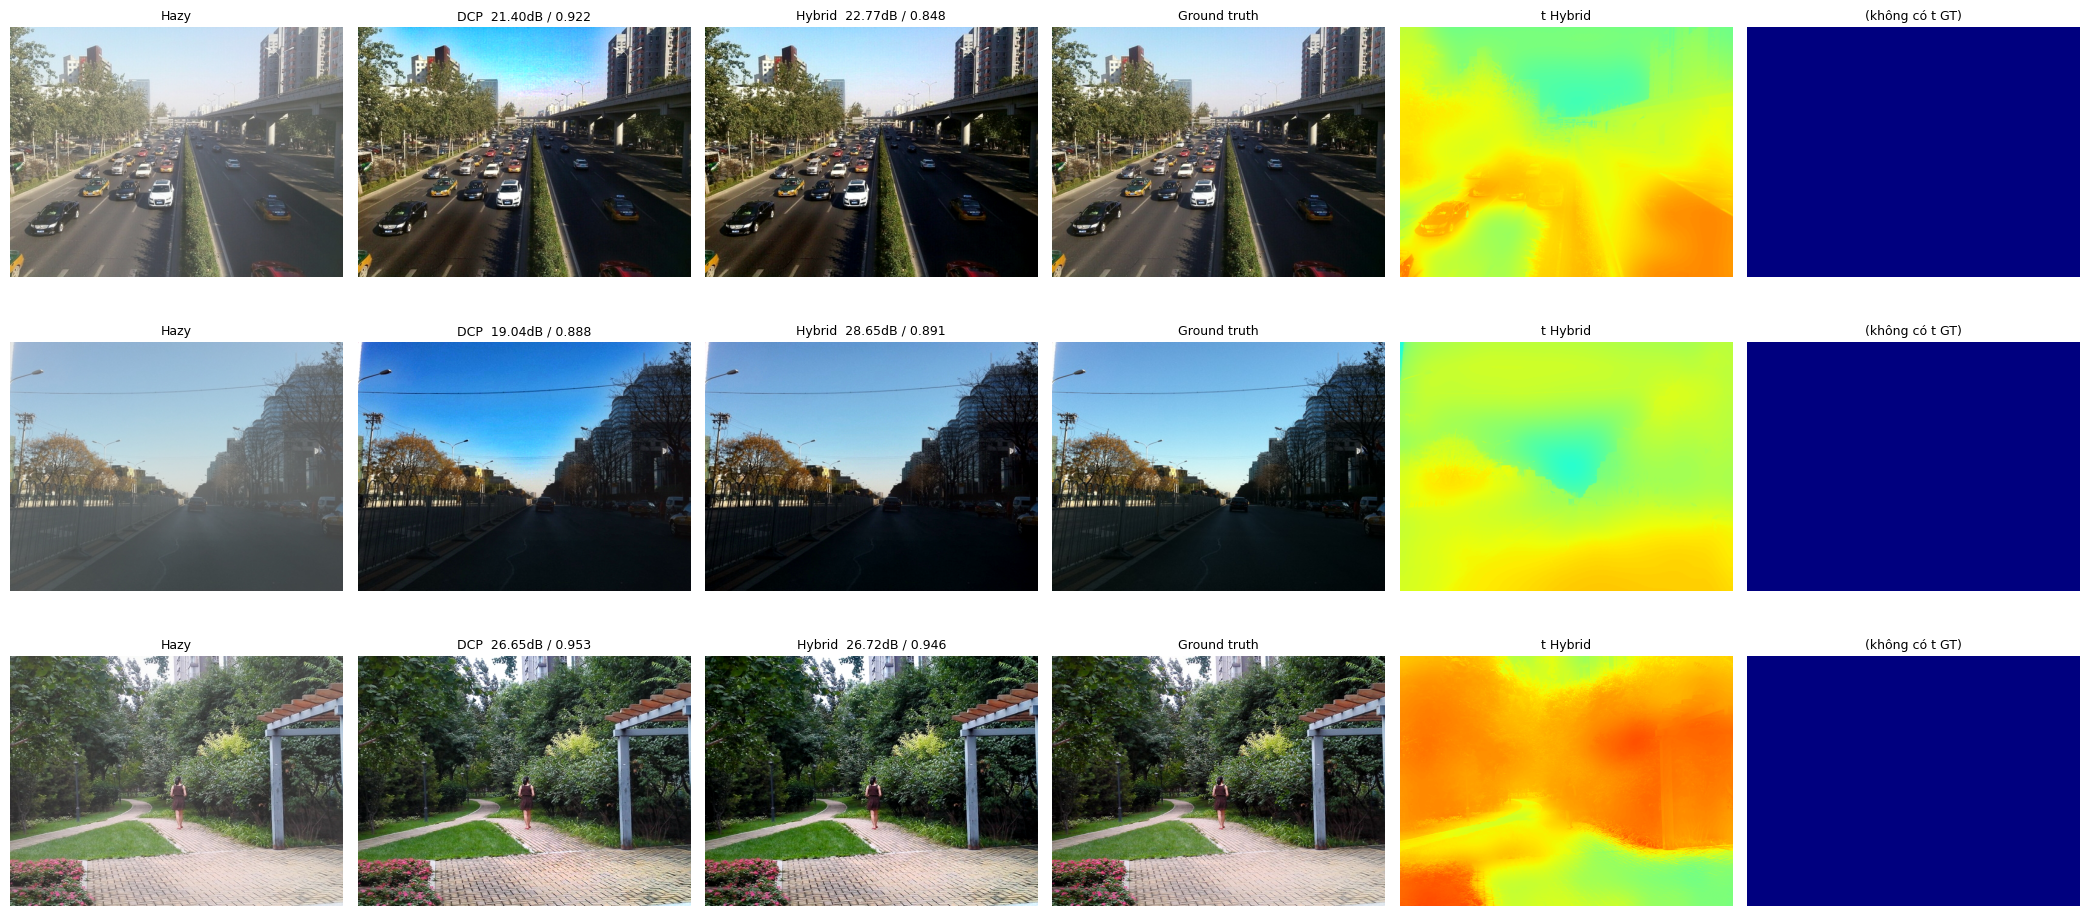

In [ ]:
def show_samples(items, model, k=4, seed=1):
    sel = random.Random(seed).sample(items, min(k, len(items)))
    fig, ax = plt.subplots(len(sel), 6, figsize=(21, 3.3 * len(sel)), squeeze=False)
    for r, it in enumerate(sel):
        img_u8 = load_rgb(it['hazy']); img = img_u8.astype(np.float32) / 255.
        gt = load_rgb(it['clear'], img.shape[:2]).astype(np.float32) / 255.
        A = estimate_A_np(img_u8)
        t_net, t_dcp = predict_t(model, img_u8, A)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        t_net_gf = np.clip(guided_filter(gray, t_net, GF_R, GF_EPS), 0, 1)
        t_dcp_gf = np.clip(guided_filter(gray, t_dcp, GF_R, GF_EPS), 0, 1)
        J_h, J_d = recover(img, t_net_gf, A), recover(img, t_dcp_gf, A)
        mh, md_ = img_metrics(J_h, gt), img_metrics(J_d, gt)
        tg = load_trans(it['trans'], img.shape[:2]) if it.get('trans') else np.zeros(img.shape[:2], np.float32)
        panels = [(img, 'Hazy'), (J_d, f"DCP  {md_['PSNR']:.2f}dB / {md_['SSIM']:.3f}"),
                  (J_h, f"Hybrid  {mh['PSNR']:.2f}dB / {mh['SSIM']:.3f}"), (gt, 'Ground truth'),
                  (t_net_gf, 't Hybrid'), (tg, 't GT' if it.get('trans') else '(không có t GT)')]
        for a, (x, ttl) in zip(ax[r], panels):
            a.imshow(x, cmap='jet' if x.ndim == 2 else None, vmin=0, vmax=1 if x.ndim == 2 else None); a.set_title(ttl, fontsize=9); a.axis('off')
    plt.tight_layout(); plt.show()

show_samples(val_items, model)
for name, items in sots_cache.items():
    print('SOTS', name); show_samples(items, model, k=3)


In [ ]:

import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CKPT_DIR = '/content/drive/MyDrive/Dehaze_Project/Checkpoints_Dehaze_v2'
if len(sys.argv) > 1 and os.path.isdir(sys.argv[1]):
    CKPT_DIR = sys.argv[1]

plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})


def plot_training(d=CKPT_DIR):
    path = os.path.join(d, 'train_history.csv')
    if not os.path.exists(path):
        print('Không thấy', path)
        return
    h = pd.read_csv(path)
    ep = h['epoch']
    dcp = float(h['val_t_mse_dcp'].mean())                       # DCP không học nên là hằng số
    best_i = int(h['val_t_mse'].idxmin())
    best_ep, best_v = int(ep[best_i]), float(h['val_t_mse'][best_i])
    improve = (h['val_t_mse_dcp'] - h['val_t_mse']) / h['val_t_mse_dcp'] * 100
    gap = h['val_t_mse'] - h['train_mse']
    smooth = h['val_t_mse'].rolling(3, center=True, min_periods=1).mean()

    fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))

    # (a) loss huấn luyện
    a = ax[0, 0]
    a.plot(ep, h['train_loss'], 'o-', ms=3, label='train loss  (MSE + 0.1·(1 − SSIM))')
    a.plot(ep, h['train_mse'], 's-', ms=3, label='train MSE  (chỉ phần MSE)')
    a.set_yscale('log')
    a.set_title('(a) Loss huấn luyện theo epoch')
    a.set_xlabel('epoch'); a.set_ylabel('giá trị (trục log)'); a.legend()

    # (b) validation so với DCP
    a = ax[0, 1]
    a.plot(ep, h['val_t_mse'], 'o-', ms=3, color='tab:blue', label='Hybrid: val t-MSE')
    a.plot(ep, smooth, '-', lw=2, color='tab:blue', alpha=0.35, label='Hybrid (trung bình trượt 3 epoch)')
    a.axhline(dcp, ls='--', color='tab:orange', label=f'DCP thuần = {dcp:.4f}')
    a.plot(ep, h['train_mse'], '-', color='tab:green', alpha=0.6, label='train MSE (patch)')
    a.scatter([best_ep], [best_v], marker='*', s=220, color='gold', edgecolor='k', zorder=5)
    a.annotate(f'tốt nhất: epoch {best_ep}\n{best_v:.5f}', (best_ep, best_v),
               xytext=(best_ep + 1.5, best_v + 0.0075), arrowprops=dict(arrowstyle='->'))
    a.set_ylim(0, dcp * 1.5)
    a.set_title('(b) val t-MSE của Hybrid so với DCP thuần (càng thấp càng tốt)')
    a.set_xlabel('epoch'); a.set_ylabel('t-MSE'); a.legend(loc='upper center', ncol=2, fontsize=9)

    # (c) mức cải thiện so với DCP
    a = ax[1, 0]
    a.bar(ep, improve, color=np.where(ep == best_ep, 'gold', 'tab:blue'), edgecolor='k', lw=0.3)
    a.axhline(improve.mean(), ls='--', color='gray', label=f'trung bình = {improve.mean():.1f}%')
    a.set_title('(c) Mức giảm val t-MSE so với DCP thuần (%)')
    a.set_xlabel('epoch'); a.set_ylabel('% giảm'); a.legend()

    # (d) chênh lệch val − train
    a = ax[1, 1]
    a.bar(ep, gap, color=np.where(gap >= 0, 'tab:red', 'tab:green'), alpha=0.75)
    a.axhline(0, color='k', lw=0.8)
    a.set_title('(d) Chênh lệch val t-MSE − train MSE  (đỏ: val cao hơn train)')
    a.set_xlabel('epoch'); a.set_ylabel('chênh lệch')

    fig.suptitle('Quá trình huấn luyện Hybrid DCP + CNN', fontsize=14, y=1.0)
    fig.tight_layout()
    out = os.path.join(d, 'plot_training_curves.png')
    fig.savefig(out, dpi=200, bbox_inches='tight')
    print('Đã lưu', out)
    plt.show()

    print('\n===== TÓM TẮT HUẤN LUYỆN =====')
    print(f'số epoch                 : {len(h)}')
    print(f'DCP thuần (val t-MSE)    : {dcp:.5f}')
    print(f'Hybrid tốt nhất          : {best_v:.5f}  (epoch {best_ep})  -> giảm {improve[best_i]:.1f}% so với DCP')
    print(f'Hybrid epoch cuối        : {h["val_t_mse"].iloc[-1]:.5f}  -> giảm {improve.iloc[-1]:.1f}%')
    print(f'train MSE epoch cuối     : {h["train_mse"].iloc[-1]:.5f}')
    if 'sec' in h:
        print(f'thời gian mỗi epoch      : {h["sec"].mean():.0f} giây  (tổng {h["sec"].sum() / 60:.0f} phút)')


def plot_eval(d=CKPT_DIR):
    path = os.path.join(d, 'final_results.csv')
    if not os.path.exists(path):
        print('Không thấy', path)
        return
    f = pd.read_csv(path)
    f['id'] = f['method'].str.extract(r'^(\d+)')[0]
    names = {'1': 'Ảnh mờ gốc', '2': 'DCP + GF', '3': 'Hybrid (thô)', '4': 'Hybrid + GF'}
    colors = {'1': '#9e9e9e', '2': '#ff7f0e', '3': '#9ecae1', '4': '#1f77b4'}
    f = f[f['id'].isin(names)]                                   # bỏ Oracle khỏi biểu đồ cột (trục sẽ bị kéo giãn)
    datasets = [x for x in ['ITS-val', 'SOTS-indoor', 'SOTS-outdoor'] if x in set(f['dataset'])]
    metrics = [('PSNR', 'PSNR (dB)  ↑ càng cao càng tốt'),
               ('SSIM', 'SSIM  ↑ càng cao càng tốt'),
               ('CIEDE2000', 'CIEDE2000  ↓ càng thấp càng tốt')]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    w = 0.2
    for ax, (m, title) in zip(axes, metrics):
        for k, (mid, nm) in enumerate(names.items()):
            vals = [f[(f['dataset'] == ds) & (f['id'] == mid)][m].mean() for ds in datasets]
            xs = np.arange(len(datasets)) + (k - 1.5) * w
            bars = ax.bar(xs, vals, w, label=nm, color=colors[mid], edgecolor='k', lw=0.3)
            for b, v in zip(bars, vals):
                ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.2f}' if m != 'SSIM' else f'{v:.3f}',
                        ha='center', va='bottom', fontsize=7)
        ax.set_xticks(np.arange(len(datasets))); ax.set_xticklabels(datasets)
        ax.set_title(title)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.07))

    # cảnh báo nếu dòng DCP+GF và Hybrid+GF giống hệt nhau (dấu hiệu chưa nạp trọng số đã train)
    cols = [c for c in ['PSNR', 'SSIM', 'CIEDE2000'] if c in f]
    a = f[f['id'] == '2'].set_index('dataset')[cols]
    b = f[f['id'] == '4'].set_index('dataset')[cols]
    same = bool(len(a) and len(b) and np.allclose(a.sort_index().values, b.sort_index().values, atol=1e-9))
    if same:
        fig.suptitle('CẢNH BÁO: "DCP + GF" và "Hybrid + GF" giống hệt nhau ở mọi chỉ số  ->  '
                     'khi đánh giá, mô hình chưa nạp trọng số đã huấn luyện (hybrid_best.pth). Chạy lại ô đánh giá sau khi nạp.',
                     color='crimson', fontsize=10, y=1.02)
        print('\nCẢNH BÁO: dòng 2 và dòng 4 trong final_results.csv giống hệt nhau -> nên đánh giá lại sau khi nạp hybrid_best.pth.')
    else:
        fig.suptitle('So sánh các phương pháp trên ITS-val và SOTS', fontsize=13, y=1.02)
    fig.tight_layout()
    out = os.path.join(d, 'plot_eval_comparison.png')
    fig.savefig(out, dpi=200, bbox_inches='tight')
    print('Đã lưu', out)
    plt.show()


if __name__ == '__main__':
    plot_training()
    plot_eval()

Không thấy /content/drive/MyDrive/Dehaze_Project/Checkpoints_Dehaze_v2/train_history.csv
Không thấy /content/drive/MyDrive/Dehaze_Project/Checkpoints_Dehaze_v2/final_results.csv


## 7. Nếu vẫn thấy bất thường - checklist nhanh
| Triệu chứng | Nguyên nhân thường gặp | Cách xử lý |
|---|---|---|
| Cell kiểm tra nhãn báo `std ~ 0` hoặc lỗi ghép cặp | Tên file trans khác quy ước | Gửi vài tên file mẫu in ra ở cell 3 để chỉnh `cands` |
| Sai số tái tạo `I = J·t + A(1−t)` lớn | Ghép nhầm trans ↔ hazy, hoặc số thứ 3 trong tên file không phải A | Xem lại quy tắc ghép |
| Val t-MSE của Hybrid **không thấp hơn** DCP sau ~10 epoch | LR chưa phù hợp / ít dữ liệu | Thử `LR=3e-4` hoặc `5e-3`, tăng `IMGS_PER_EPOCH`, tăng `ch` lên 48/64 |
| t-MSE tốt nhưng PSNR ảnh khôi phục thấp | Lỗi nằm ở `A` hoặc `t_min` | So với dòng Oracle; thử `t_min=0.15`, hoặc ước lượng `A` ở độ phân giải cao hơn |
| PSNR SOTS-outdoor thấp | ITS là ảnh trong nhà (lệch miền) | Huấn luyện thêm trên OTS |
| Muốn tiếp tục train | - | Đặt `RESUME=True` (chỉ với checkpoint v2) |

```markdown
# CHƯƠNG 2: CƠ SỞ LÝ THUYẾT VÀ PHÂN TÍCH THIẾT KẾ HỆ THỐNG

## 2.1. Mô hình toán học của sự suy giảm chất lượng ảnh do sương mù

Quá trình suy giảm chất lượng hình ảnh trong điều kiện khí quyển có sương mù được biểu diễn một cách rộng rãi bằng mô hình tán xạ ánh sáng của Koschmieder:
$$I(x) = J(x)t(x) + A(1 - t(x))$$

Trong đó:
* $I(x)$ là cường độ sáng của ảnh có sương mù nhận được tại pixel $x$.
* $J(x)$ là ảnh gốc rõ nét cần khôi phục (cảnh thực tế không có sương).
* $A$ là vectơ hằng số biểu thị ánh sáng khí quyển toàn cục (Atmospheric Light).
* $t(x)$ là bản đồ truyền dẫn môi trường (Transmission Map), mô tả tỷ lệ ánh sáng không bị tán xạ truyền đến cảm biến camera.

Để khôi phục lại ảnh rõ nét $J(x)$, hệ thống cần giải bài toán ngược bằng cách ước lượng đồng thời hai tham số chưa biết là $A$ và $t(x)$:
$$J(x) = \frac{I(x) - A}{\max(t(x), t_{min})} + A$$

## 2.2. Phân tích thiết kế hệ thống lai đề xuất (Hybrid DCP-CNN)

Hệ thống đề xuất khắc phục nhược điểm của cả phương pháp vật lý truyền thống và phương pháp học sâu thuần túy bằng việc thiết kế một quy trình kết hợp chặt chẽ:

```
[ Ảnh Hazy Đầu Vào (I) ]
       │
       ├─────────────────────────┐
       ▼                         ▼
[ Ước lượng A trên GPU ]   [ Lọc Min-pooling (DCP) ]
       │                         │
       │                         ▼
       │                   [ Bản đồ truyền dẫn thô t_DCP ]
       │                         │
       └───────────┬─────────────┘
                   ▼
           [ Ghép kênh (Concat 5-Kênh) ] ────► (RGB, Dark Channel, t_DCP)
                   │
                   ▼
           [ Mạng Hybrid Transmission CNN ]
                   │ (Học phần sai lệch Residual)
                   ▼
           [ Bản đồ truyền dẫn tinh chế t_Net ]
                   │
                   ▼
           [ Bộ lọc dẫn đường (Guided Filter) ]
                   │ (Khử răng cưa & sắc nét biên)
                   ▼
           [ Bản đồ truyền dẫn tối ưu t_Final ]
                   │
                   ▼
           [ Khôi phục ảnh rõ nét (J) ]
```
```

```markdown
## 2.3. Các thành phần chính của kiến trúc đề xuất

### 2.3.1. Mô-đun ước lượng ánh sáng khí quyển ($A$) thời gian thực
Để tối ưu hóa hiệu năng, hằng số khí quyển $A$ được tính toán nhanh chóng thông qua kỹ thuật co ảnh xuống tỉ lệ $1/4$ trước khi lọc tối thiểu.
* **Thuật toán:** Trích xuất $0.1\%$ số lượng pixel có giá trị kênh tối lớn nhất trên ảnh thu nhỏ.
* **Ý nghĩa:** Tránh thắt nút cổ chai (bottleneck) tính toán mà vẫn đảm bảo độ chính xác vật lý cao khi chạy trực tiếp trên GPU.

### 2.3.2. Mạng HybridTransmissionCNN (Residual Transmission)
Mạng nơ-ron được thiết kế cực kỳ gọn nhẹ (~20k tham số) với mục tiêu không phải học cách tạo ra bản đồ truyền dẫn từ đầu, mà chỉ học cách **sửa sai (residual)** cho kết quả thô từ thuật toán DCP:
$$t_{final}(x) = \text{Clamp}(t_{DCP}(x) + \mathcal{F}_{CNN}(x), 0, 1)$$

* **Cấu trúc mạng:**
  * **Lớp đầu vào:** Nhận vào ảnh $5$ kênh bao gồm: 3 kênh màu RGB của ảnh sương mù ($I$), 1 kênh ảnh tối thô ($Dark$) và 1 kênh bản đồ truyền dẫn thô của DCP ($t_{DCP}$).
  * **Các tầng ẩn (Body):** Gồm các lớp tích chập với các bước giãn nở khác nhau (Dilation rate = 1, 2, 4) kết hợp hàm kích hoạt PReLU. Thiết kế này giúp mở rộng trường thụ cảm hiệu dụng lên khoảng $17 \times 17$ pixel để nắm bắt ngữ cảnh không gian rộng hơn mà không làm tăng số lượng tham số.
  * **Khởi tạo thông minh:** Trọng số và bias của lớp tích chập cuối cùng được khởi tạo bằng $0$. Do đó, tại thời điểm bắt đầu huấn luyện, đầu ra của mạng trùng khớp hoàn toàn với kết quả vật lý của thuật toán DCP thô ($t_{final} = t_{DCP}$).
  * **Cơ chế Straight-Through Estimator (STE) Clamp:** Đảm bảo quá trình truyền ngược gradient không bị triệt tiêu khi giá trị bị cắt trong khoảng $[0, 1]$ trong lúc huấn luyện.

### 2.3.3. Bộ lọc dẫn đường (Guided Filter)
Bản đồ truyền dẫn dự đoán từ CNN thường bị hiện tượng mờ nhòe ở các cạnh biên vật thể. Hệ thống tích hợp một bộ lọc dẫn đường (Guided Filter) với ảnh hướng dẫn là ảnh xám của ảnh đầu vào ($I$) để khôi phục và làm sắc nét các cấu trúc cạnh mịn, loại bỏ hiệu ứng quầng sáng (halo artifacts) quanh vật thể.
```

```markdown
## 2.3. Chi tiết thuật toán và Phân tích chuyên sâu các thành phần

### 2.3.1. Mô-đun ước lượng ánh sáng khí quyển toàn cục (Global Atmospheric Light $A$)
Trong mô hình vật lý tán xạ, ánh sáng khí quyển $A$ quyết định trực tiếp đến mức độ bù màu và khôi phục tương phản. Nếu ước lượng $A$ quá lớn, ảnh khôi phục sẽ bị tối đen và mất chi tiết ở vùng tối. Ngược lại, nếu $A$ quá thấp, hiện tượng sương mù vẫn sẽ tồn tại dai dẳng.

* **Hạn chế của phương pháp truyền thống:** Các thuật toán kinh điển thường tìm pixel sáng nhất trong ảnh đầu vào làm $A$. Cách tiếp cận này rất dễ bị đánh lừa bởi các vật thể tự phát sáng hoặc có màu trắng tự nhiên (như vạch kẻ đường, đèn xe, biển báo).
* **Giải pháp tối ưu hóa đề xuất:**
  1. **Bước 1 (Thu nhỏ không gian):** Co ảnh gốc xuống tỷ lệ $\frac{1}{4}$ bằng phép nội suy vùng (`cv2.INTER_AREA`). Việc này loại bỏ các nhiễu tần số cao cục bộ và giảm độ phức tạp tính toán đi 16 lần.
  2. **Bước 2 (Lọc tối thiểu):** Áp dụng phép xói mòn (Erode/Min-pooling) trên kênh tối để tìm ra vùng có mật độ sương mù dày đặc nhất.
  3. **Bước 3 (Thống kê tích lũy):** Chỉ lấy $0.1\%$ số lượng pixel có giá trị lớn nhất trong kênh tối này, sau đó tính trung bình cộng giá trị màu RGB gốc tương ứng của chúng để làm $A$.

### 2.3.2. Phân tích toán học cơ chế Residual của HybridTransmissionCNN
Mô hình thiết kế dựa trên triết lý: **"Đứng trên vai người khổng lồ"**. Thay vì ép một mạng CNN nhỏ phải học toàn bộ cấu trúc vật lý phức tạp từ đầu, mạng chỉ học hàm hiệu chỉnh sai số $\mathcal{F}_{CNN}(x)$:

$$\text{Bản đồ truyền dẫn thực tế (GT)} \approx t_{DCP}(x) + \mathcal{F}_{CNN}(x)$$

* **Cơ chế Triệt tiêu Gradient & Giải pháp STE (Straight-Through Estimator):**
  Khi tính toán thực tế, bản đồ truyền dẫn bắt buộc phải nằm trong giới hạn vật lý $[0, 1]$. Tuy nhiên, hàm kẹp cứng (Hard Clamp) truyền thống sẽ làm triệt tiêu hoàn toàn đạo hàm (gradient = 0) ở các vùng bị kẹp, khiến mạng không thể học tiếp. Chúng tôi giải quyết bằng cơ chế **Straight-Through Estimator (STE)**:
  $$\text{Forward:} \quad t_{out} = \text{Clamp}(t, 0, 1)$$
  $$\text{Backward:} \quad \frac{\partial L}{\partial t} \approx \frac{\partial L}{\partial t_{out}}$$
  Trong PyTorch, kỹ thuật này được thực hiện gọn gàng qua toán tử: `t + (t_hard - t).detach()` giúp gradient đi qua bộ kẹp một cách thông suốt.
* **Sự kết hợp của Tích chập giãn (Dilated Convolution):**
  Sử dụng các dilation rate lần lượt là $1, 2, 4$ giúp mở rộng vùng bao quát (receptive field) từ $3 \times 3$ lên tới $17 \times 17$ mà không cần tăng số lượng tham số hay sử dụng các tầng Pooling làm mất độ phân giải không gian.

### 2.3.3. Cơ chế Lọc dẫn đường (Guided Filter - GF) giữ biên cấu trúc
Mạng CNN do có các lớp tích chập và hàm kích hoạt thường tạo ra bản đồ truyền dẫn bị mờ nhòe ở ranh giới giữa vật thể gần và nền xa (gây ra hiện tượng Halo - vầng hào quang sau khi khử sương).

Bộ lọc dẫn đường (Guided Filter) đóng vai trò là một bộ lọc song phương tuyến tính cục bộ. Nó giả định rằng đầu ra $q$ là một phép biến đổi tuyến tính của ảnh dẫn đường $I$ (ở đây là ảnh xám của ảnh hazy) trong một cửa sổ cục bộ $\omega_k$:
$$q_i = a_k I_i + b_k, \quad \forall i \in \omega_k$$

Các hệ số $a_k$ và $b_k$ được xác định bằng cách cực tiểu hóa sai số bình phương giữa $q$ và bản đồ truyền dẫn thô $p$ từ mạng CNN:
$$E(a_k, b_k) = \sum_{i \in \omega_k} ((a_k I_i + b_k - p_i)^2 + \epsilon a_k^2)$$

Trong đó $\epsilon$ là tham số điều hòa tránh hệ số $a_k$ quá lớn. Nhờ thuật toán này, các chi tiết góc cạnh sắc nét của vật thể từ ảnh gốc $I$ sẽ được truyền dẫn và bảo toàn sang bản đồ truyền dẫn cuối cùng.
```

In [ ]:
# MINH HỌA TRỰC QUAN CƠ CHẾ HOẠT ĐỘNG CỦA 3 THÀNH PHẦN CHÍNH
import numpy as np
import matplotlib.pyplot as plt
import cv2

# 1. Tạo một ảnh giả lập đơn giản: Một khối hộp xám trên nền sáng (chứa biên sắc nét)
img_size = 128
I_test = np.ones((img_size, img_size), dtype=np.float32) * 0.8
I_test[32:96, 32:96] = 0.3 # Khối hộp xám

# Giả lập bản đồ truyền dẫn thô từ CNN bị nhòe cạnh (Blurry transmission)
t_raw = cv2.GaussianBlur(I_test, (15, 15), 5)

# 2. Thực hiện Guided Filter để phục hồi biên sắc nét
r_test = 8
eps_test = 0.01

def box_filter_demo(img, r):
    return cv2.boxFilter(img, -1, (2*r+1, 2*r+1), borderType=cv2.BORDER_REFLECT)

def guided_filter_demo(I, p, r, eps):
    mean_I = box_filter_demo(I, r)
    mean_p = box_filter_demo(p, r)
    mean_Ip = box_filter_demo(I * p, r)
    cov_Ip = mean_Ip - mean_I * mean_p

    mean_II = box_filter_demo(I * I, r)
    var_I = mean_II - mean_I * mean_I

    a = cov_Ip / (var_I + eps)
    b = mean_p - a * mean_I

    mean_a = box_filter_demo(a, r)
    mean_b = box_filter_demo(b, r)
    return mean_a * I + mean_b

t_guided = guided_filter_demo(I_test, t_raw, r_test, eps_test)

# 3. Vẽ biểu đồ minh họa mặt cắt tín hiệu (1D Profile) cắt ngang qua biên của vật thể
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(I_test, cmap='gray')
plt.axhline(64, color='red', linestyle='--', alpha=0.8, label='Đường cắt ngang phân tích')
plt.title("Ảnh Dẫn Đường gốc I (Biên Sắc Nét)")
plt.axis('off')
plt.legend()

plt.subplot(1, 2, 2)
y_true = I_test[64, :]
y_blur = t_raw[64, :]
y_guided = t_guided[64, :]

plt.plot(y_true, 'k-', lw=2, label='Biên gốc của vật thể (Mục tiêu)')
plt.plot(y_blur, 'r--', lw=1.5, label='Bản đồ truyền dẫn từ CNN (Bị nhòe cạnh)')
plt.plot(y_guided, 'b-', lw=2, label='Sau khi qua Guided Filter (Khôi phục biên)')
plt.title("Mặt cắt tín hiệu truyền dẫn (Pixel thứ 64)")
plt.xlabel("Tọa độ X (pixel)")
plt.ylabel("Giá trị Truyền Dẫn (t)")
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()